# Customer Propensity & Campaign Valuation — Bank Term-Deposit Telemarketing

**Target role:** Axis Bank BIU (Business Intelligence Unit) — Analytics
**Data:** UCI Bank Marketing, `bank-additional-full.csv` — 41,188 outbound calls by a Portuguese retail bank, May 2008 – Nov 2010

## Business question
A bank's outbound call centre sells term deposits. Every call costs money and most calls don't convert. The analytics team has to answer four things:

1. **Whom should we call?** — a propensity score that ranks customers
2. **Is the campaign worth running, and for whom?** — unit economics / valuation
3. **Through which channel, and how many times?** — channel and contact-frequency policy
4. **Why did performance change?** — root-cause analysis of conversion drift

## Mapping to the JD
| JD responsibility | Section |
|---|---|
| Propensity-based models, predictive analytics, AI/ML | §5 – §7, §9 (incl. F1), §10 |
| Root-cause analysis using predictive and descriptive analytics | §4, §8 |
| Exploratory analytics to find pockets of opportunity | §3 |
| Profitability / valuation analysis | §11 |
| Optimise channel / offer mix | §12 |
| Dashboards and reports | §10 (model monitoring), §14 (CSV exports for Excel / Power BI) |

## Three design decisions that separate this from a typical tutorial
- **`duration` (call length) is excluded.** It is only known after the call ends and is the strongest predictor in the file. A model that uses it cannot be used to decide whom to call.
- **Validation is out-of-time, not a random split.** The rows are chronological and conversion moves from ~5% to ~50%. A random split lets the model learn from the future and overstates accuracy (§5).
- **Macro indicators (Euribor, employment, CPI) are kept out of the ranking model.** They are identical for everyone called on a given day, so they tell you *when* conversion will be high, not *whom* to call — and they generalise badly to new periods (§5).

## 1. Setup and data loading
Put `bank_marketing.zip` (the UCI download, which contains nested zips) or `bank-additional-full.csv` in the same folder as this notebook. The loader finds the CSV either way.

Requirements: pandas, numpy, matplotlib, scipy, scikit-learn ≥ 1.2, statsmodels.

In [1]:
import os, io, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter
from scipy.special import logit, expit
from scipy.optimize import brentq
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import (roc_auc_score, brier_score_loss, f1_score, fbeta_score, precision_score,
                             recall_score, precision_recall_curve)
import statsmodels.formula.api as smf

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3})
SEED = 42
BRAND, GREY = '#97144d', '#9aa5b1'
OUT_DIR = 'outputs'
os.makedirs(OUT_DIR, exist_ok=True)


def _find_csv_in_zip(zf, target='bank-additional-full.csv'):
    """Search a zip (and any zips nested inside it) for the target CSV."""
    for name in zf.namelist():
        if name.startswith('__MACOSX'):
            continue
        base = name.split('/')[-1]
        if base == target:
            with zf.open(name) as f:
                return pd.read_csv(f, sep=';')
        if base.endswith('.zip'):
            with zipfile.ZipFile(io.BytesIO(zf.read(name))) as inner:
                found = _find_csv_in_zip(inner, target)
                if found is not None:
                    return found
    return None


def load_data():
    csv_paths = ['bank-additional-full.csv', 'bank-additional/bank-additional-full.csv',
                 'data/bank-additional-full.csv', 'data/bank-additional/bank-additional-full.csv']
    zip_paths = ['bank_marketing.zip', 'bank+marketing.zip', 'bank-additional.zip',
                 'data/bank_marketing.zip', 'data/bank+marketing.zip', 'data/bank-additional.zip']
    for p in csv_paths:
        if os.path.exists(p):
            print('Loaded', p)
            return pd.read_csv(p, sep=';')
    for p in zip_paths:
        if os.path.exists(p):
            with zipfile.ZipFile(p) as zf:
                found = _find_csv_in_zip(zf)
            if found is not None:
                print('Loaded bank-additional-full.csv from', p)
                return found
    raise FileNotFoundError('Place bank_marketing.zip or bank-additional-full.csv next to this notebook.')


raw = load_data()
print(raw.shape)
raw.head()

Loaded bank-additional-full.csv from bank_marketing.zip
(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 2. Rebuild the timeline and audit the data

The file has no year column, but UCI documents that rows are ordered by date from May 2008 to November 2010. So the year increments every time the month number goes backwards (e.g. Dec → Mar). The assertion checks the result against the documented start and end months.

In [2]:
MONTHS = {m: i for i, m in enumerate(['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug',
                                      'sep', 'oct', 'nov', 'dec'], start=1)}
df = raw.copy()
df['target'] = (df['y'] == 'yes').astype(int)
df['month_num'] = df['month'].map(MONTHS)
df['year'] = 2008 + (df['month_num'].diff() < 0).cumsum()
df['ym'] = df['year'] * 100 + df['month_num']
df['period'] = pd.to_datetime(pd.DataFrame({'year': df['year'], 'month': df['month_num'], 'day': 1})).dt.strftime('%b-%y')

assert df['ym'].iloc[0] == 200805 and df['ym'].iloc[-1] == 201011, 'Timeline reconstruction failed'
print(f"{len(df):,} calls | {df['ym'].nunique()} months | {df['period'].iloc[0]} to {df['period'].iloc[-1]}")
print(f"Overall conversion: {df['target'].mean():.1%}")
df.groupby('year').agg(customers=('target', 'size'), subscribers=('target', 'sum'), conversion=('target', 'mean')).round(3)

41,188 calls | 26 months | May-08 to Nov-10
Overall conversion: 11.3%


,customers,subscribers,conversion
year,,,
2008,27690,1339,0.048
2009,11440,2228,0.195
2010,2058,1073,0.521


### 2.1 Data audit: leakage, sentinels, rare categories

In [3]:
# (a) Leakage: call duration is only known once the call is over
dur = (df.groupby(pd.cut(df['duration'], [-1, 60, 120, 240, 480, 5000],
                         labels=['<1 min', '1-2 min', '2-4 min', '4-8 min', '8+ min']), observed=True)['target']
         .agg(customers='size', conversion='mean'))
print('(a) Conversion by call duration — near-deterministic, and unknowable before dialling:')
print(dur.round(3), '\n')

# (b) Sentinel values
print(f"(b) pdays == 999 ('never contacted before'): {(df['pdays'] == 999).mean():.1%} of rows")
print("    poutcome vs pdays-known:")
print(pd.crosstab(df['poutcome'], df['pdays'] != 999, colnames=['pdays known']), '\n')

# (c) 'unknown' is a real category here, not missing-at-random
unk = (df[['job', 'marital', 'education', 'default', 'housing', 'loan']] == 'unknown').sum()
print("(c) 'unknown' counts:", unk.to_dict())
print(f"    housing unknown <=> loan unknown on the same rows: {((df['housing'] == 'unknown') == (df['loan'] == 'unknown')).all()}")
print(f"(d) Rare levels: default='yes' -> {(df['default'] == 'yes').sum()} rows, education='illiterate' -> {(df['education'] == 'illiterate').sum()} rows")

(a) Conversion by call duration — near-deterministic, and unknowable before dialling:
          customers  conversion
duration                       
<1 min         4286       0.000
1-2 min        8631       0.019
2-4 min       13263       0.067
4-8 min        9720       0.145
8+ min         5288       0.412 

(b) pdays == 999 ('never contacted before'): 96.3% of rows
    poutcome vs pdays-known:
pdays known  False  True 
poutcome                 
failure       4110    142
nonexistent  35563      0
success          0   1373 

(c) 'unknown' counts: {'job': 330, 'marital': 80, 'education': 1731, 'default': 8597, 'housing': 990, 'loan': 990}
    housing unknown <=> loan unknown on the same rows: True
(d) Rare levels: default='yes' -> 3 rows, education='illiterate' -> 18 rows


**What the audit tells us**
- **Duration is target leakage.** Calls under a minute almost never convert, calls over eight minutes convert ~40% of the time. It describes the outcome rather than predicting it, so it is dropped (UCI's own documentation says the same).
- **`pdays = 999` is a sentinel**, not a number. It is redundant with `poutcome` (every past success has a known `pdays`), so `pdays` is dropped and `poutcome` + `previous` carry the history.
- **`unknown` is informative** — e.g. `default = unknown` usually means the bank couldn't verify credit status. It stays as its own category.
- `housing` and `loan` are unknown on exactly the same 990 rows, so they are combined into one `products` field to avoid duplicate columns.

In [4]:
df['default'] = df['default'].replace({'yes': 'unknown'})            # 3 rows: neither is a clean 'no'
df['education'] = df['education'].replace({'illiterate': 'basic.4y'})  # 18 rows
df['products'] = df['housing'] + '/' + df['loan']                     # housing loan / personal loan
df['age_band'] = pd.cut(df['age'], [0, 25, 30, 40, 50, 60, 120],
                        labels=['<=25', '26-30', '31-40', '41-50', '51-60', '60+']).astype(str)
df['previous'] = df['previous'].clip(upper=3)

CAT_FEATURES = ['job', 'marital', 'education', 'default', 'products', 'contact', 'poutcome', 'age_band']
NUM_FEATURES = ['previous']
MACRO = ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
TIMING = ['month', 'day_of_week']

feature_policy = pd.DataFrame([
    ['Customer profile', 'age_band, job, marital, education', 'Yes', 'Yes', ''],
    ['Credit & products', 'default, products (housing/loan)', 'Yes', 'Yes', ''],
    ['Channel', 'contact (cellular / landline)', 'Yes', 'Yes', 'Also analysed as a policy lever (§12)'],
    ['Past campaign history', 'previous, poutcome', 'Yes', 'Yes', 'pdays dropped (sentinel, redundant)'],
    ['Macro-economic', ', '.join(MACRO), 'Yes', 'No', 'Same for everyone on a given day: explains WHEN, not WHOM (§5)'],
    ['Calendar', 'month, day_of_week', 'Yes', 'No', 'Calendar labels do not carry over to future periods (§5)'],
    ['In-campaign', 'campaign (calls made so far)', 'Only mid-campaign', 'No', 'Used for the contact-cap policy (§12)'],
    ['Call outcome', 'duration', 'No — after the call', 'No', 'Target leakage'],
], columns=['Group', 'Columns', 'Known before the call?', 'In targeting model?', 'Note'])
feature_policy

,Group,Columns,Known before the call?,In targeting model?,Note
0,Customer profile,"age_band, job, marital, education",Yes,Yes,
1,Credit & products,"default, products (housing/loan)",Yes,Yes,
2,Channel,contact (cellular / landline),Yes,Yes,Also analysed as a policy lever (§12)
3,Past campaign history,"previous, poutcome",Yes,Yes,"pdays dropped (sentinel, redundant)"
4,Macro-economic,"emp.var.rate, cons.price.idx, cons.conf.idx, e...",Yes,No,Same for everyone on a given day: explains WHE...
5,Calendar,"month, day_of_week",Yes,No,Calendar labels do not carry over to future pe...
6,In-campaign,campaign (calls made so far),Only mid-campaign,No,Used for the contact-cap policy (§12)
7,Call outcome,duration,No — after the call,No,Target leakage


## 3. Exploratory analysis — volume, conversion and pockets of opportunity

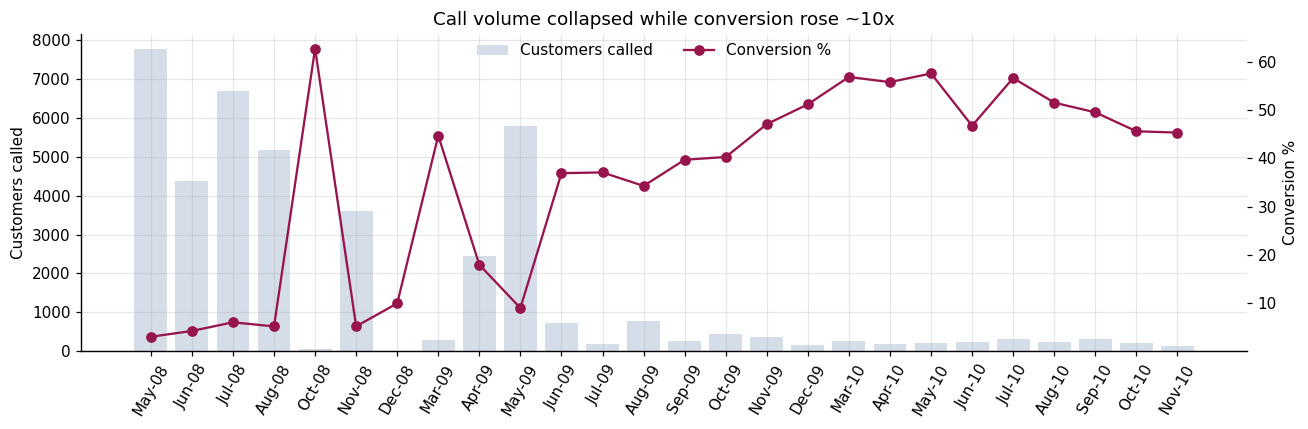

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25
period,May-08,Jun-08,Jul-08,Aug-08,Oct-08,Nov-08,Dec-08,Mar-09,Apr-09,May-09,Jun-09,Jul-09,Aug-09,Sep-09,Oct-09,Nov-09,Dec-09,Mar-10,Apr-10,May-10,Jun-10,Jul-10,Aug-10,Sep-10,Oct-10,Nov-10
customers,7763,4374,6685,5175,67,3616,10,282,2458,5794,715,178,770,267,447,357,172,264,174,212,229,311,233,303,204,128
conversion,0.031,0.043,0.061,0.052,0.627,0.053,0.1,0.447,0.18,0.09,0.369,0.371,0.343,0.397,0.403,0.471,0.512,0.568,0.557,0.575,0.467,0.566,0.515,0.495,0.456,0.453
avg_calls,2.513,3.357,3.236,2.841,1.0,1.912,1.0,2.511,1.936,2.362,1.751,2.185,1.725,1.678,1.521,1.922,2.227,1.875,2.109,1.887,1.751,2.113,1.906,1.858,1.779,1.805
euribor3m,4.858,4.932,4.962,4.965,4.924,4.115,3.493,1.646,1.412,1.294,1.258,1.025,0.866,0.783,0.735,0.716,0.713,0.646,0.646,0.686,0.733,0.85,0.899,0.88,0.995,1.042


In [5]:
monthly = (df.groupby('ym')
             .agg(period=('period', 'first'), customers=('target', 'size'), subscribers=('target', 'sum'),
                  conversion=('target', 'mean'), avg_calls=('campaign', 'mean'), euribor3m=('euribor3m', 'mean'))
             .reset_index())

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.bar(monthly['period'], monthly['customers'], color='#d5dde8', label='Customers called')
ax1.set_ylabel('Customers called')
ax1.tick_params(axis='x', rotation=60)
ax2 = ax1.twinx()
ax2.plot(monthly['period'], monthly['conversion'] * 100, color=BRAND, marker='o', label='Conversion %')
ax2.set_ylabel('Conversion %')
ax2.grid(False)
ax1.set_title('Call volume collapsed while conversion rose ~10x')
fig.legend(loc='upper center', ncol=2, bbox_to_anchor=(0.5, 0.92), frameon=False)
plt.tight_layout()
plt.show()
monthly[['period', 'customers', 'conversion', 'avg_calls', 'euribor3m']].round(3).T

Two regimes: mass calling in mid-2008 (~5,000–7,700 customers a month at 3–6% conversion) and small, high-yield waves from late 2009 (~150–450 customers at 40–57%). Any model has to survive that shift, which is why everything below is validated on later months than it was trained on.

### 3.1 Segment view: raw conversion vs. month-adjusted index
Raw segment conversion is misleading here, because segments were not called evenly over time. The **month-adjusted index** compares a segment's subscribers with the number expected if it had converted at the average rate of the months it was actually called in. 100 = average; 150 = 1.5× better than other customers called in the same months.

In [6]:
df['month_rate'] = df.groupby('ym')['target'].transform('mean')
OVERALL_RATE = df['target'].mean()


def segment_view(col):
    g = df.groupby(col).agg(customers=('target', 'size'), subscribers=('target', 'sum'),
                            conversion=('target', 'mean'), expected=('month_rate', 'sum'))
    g['raw_index'] = g['conversion'] / OVERALL_RATE * 100
    g['month_adj_index'] = g['subscribers'] / g['expected'] * 100
    return g.drop(columns='expected').sort_values('month_adj_index', ascending=False).round(3)


segments = {c: segment_view(c) for c in ['poutcome', 'contact', 'age_band', 'job', 'default', 'education', 'products']}
for c in ['poutcome', 'contact', 'age_band', 'job', 'default']:
    t = segments[c][['customers', 'conversion', 'raw_index', 'month_adj_index']].copy()
    t['conversion'] = (t['conversion'] * 100).round(1).astype(str) + '%'
    t[['raw_index', 'month_adj_index']] = t[['raw_index', 'month_adj_index']].round(0).astype(int)
    print(f'--- {c} ---')
    print(t, '\n')

--- poutcome ---
             customers conversion  raw_index  month_adj_index
poutcome                                                     
success           1373      65.1%        578              161
nonexistent      35563       8.8%         78               97
failure           4252      14.2%        126               70 

--- contact ---
           customers conversion  raw_index  month_adj_index
contact                                                    
cellular       26144      14.7%        131              105
telephone      15044       5.2%         46               82 

--- age_band ---
          customers conversion  raw_index  month_adj_index
age_band                                                  
<=25           1666      20.9%        186              112
60+             910      45.5%        404              110
26-30          5717      13.6%        120              106
51-60          6270      10.7%         95              102
31-40         16385       9.7%         87 

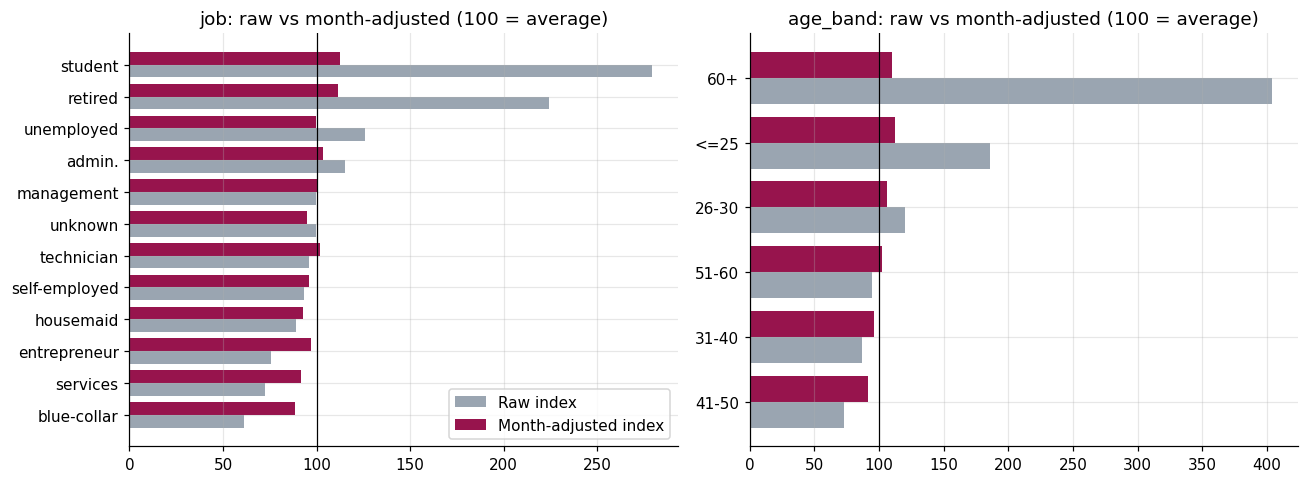

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col in zip(axes, ['job', 'age_band']):
    s = segments[col].sort_values('raw_index')
    y = np.arange(len(s))
    ax.barh(y - 0.2, s['raw_index'], height=0.4, color=GREY, label='Raw index')
    ax.barh(y + 0.2, s['month_adj_index'], height=0.4, color=BRAND, label='Month-adjusted index')
    ax.axvline(100, color='black', lw=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels(s.index)
    ax.set_title(f'{col}: raw vs month-adjusted (100 = average)')
axes[0].legend(loc='lower right')
plt.tight_layout()
plt.show()

**Read this chart before believing any "students and retirees convert 3x" headline.** Students and retirees were called disproportionately in the high-conversion months of 2009–10, so their raw rate is inflated. Adjusted for timing, most of the job gap shrinks, while a few signals survive:
- **Past campaign success** is by far the strongest customer signal.
- **Mobile (cellular) contacts** convert well above landline contacts called in the same months.
- **Age extremes** (≤25 and 60+) stay above average; **`default = unknown`** stays below.

These are the pockets the propensity model should exploit. §8 tests them formally with month fixed effects.

## 4. Root cause: why did conversion jump from ~5% to ~52%?

Two candidate explanations:
1. **Mix** — the bank started calling better customers (more past responders, more mobile numbers).
2. **Rate** — the same kind of customer became more likely to say yes (environment, offer, or selection on information not in the data).

A shift-share decomposition splits the 2008 → 2010 change into those two parts, using segments built from the strongest observable signals.

In [8]:
df['seg'] = df['poutcome'] + ' | ' + df['contact'] + ' | ' + np.where(df['age'] < 30, '<30', np.where(df['age'] >= 60, '60+', '30-59'))


def shift_share(a, b, seg='seg'):
    sa = a.groupby(seg)['target'].agg(n_a='size', rate_a='mean')
    sb = b.groupby(seg)['target'].agg(n_b='size', rate_b='mean')
    t = sa.join(sb, how='outer')
    t[['n_a', 'n_b']] = t[['n_a', 'n_b']].fillna(0)
    t['rate_a'] = t['rate_a'].fillna(a['target'].mean())   # segment absent in base year -> base-year average
    t['rate_b'] = t['rate_b'].fillna(b['target'].mean())
    t['w_a'], t['w_b'] = t['n_a'] / t['n_a'].sum(), t['n_b'] / t['n_b'].sum()
    mix = ((t['w_b'] - t['w_a']) * t['rate_a']).sum()
    rate = ((t['rate_b'] - t['rate_a']) * t['w_b']).sum()
    return mix, rate, t


a, b = df[df['year'] == 2008], df[df['year'] == 2010]
mix, rate, ss_table = shift_share(a, b)
total = b['target'].mean() - a['target'].mean()
print(f"Conversion 2008: {a['target'].mean():.1%}  ->  2010: {b['target'].mean():.1%}  (change {total * 100:+.1f} pts)")
print(f"  Mix effect  (who was called):            {mix * 100:+.1f} pts  ({mix / total:.0%} of change)")
print(f"  Rate effect (same segment, better result): {rate * 100:+.1f} pts  ({rate / total:.0%} of change)\n")
print(ss_table.sort_values('n_b', ascending=False)[['n_a', 'rate_a', 'n_b', 'rate_b']].round(3).head(10))

Conversion 2008: 4.8%  ->  2010: 52.1%  (change +47.3 pts)
  Mix effect  (who was called):            +0.7 pts  (2% of change)
  Rate effect (same segment, better result): +46.6 pts  (98% of change)

                                     n_a  rate_a  n_b  rate_b
seg                                                          
nonexistent | cellular | 30-59   11791.0   0.057  365   0.586
success | cellular | 30-59          32.0   0.094  336   0.789
failure | cellular | 30-59         624.0   0.034  273   0.319
nonexistent | telephone | 30-59  12024.0   0.039  153   0.190
success | cellular | <30             0.0   0.048  140   0.750
failure | cellular | <30            28.0   0.036  132   0.394
nonexistent | cellular | <30      1429.0   0.070  121   0.537
nonexistent | cellular | 60+        72.0   0.083  113   0.460
success | cellular | 60+             0.0   0.048  106   0.802
failure | cellular | 60+             0.0   0.048   84   0.452


### 4.1 Was there any signal to learn in the first campaign wave?
In-year 5-fold cross-validated AUC of a simple customer-feature model, year by year. This answers: *within a single period, how rankable were customers at all?*

In [9]:
def make_pipeline(model, cats, nums):
    pre = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=30, sparse_output=False), cats),
        ('num', StandardScaler(), nums)])
    return Pipeline([('pre', pre), ('model', model)])


def lr_model():
    return LogisticRegression(max_iter=2000)


def gb_model():
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                          min_samples_leaf=100, l2_regularization=1.0, random_state=SEED)


FEATURES = CAT_FEATURES + NUM_FEATURES
signal = []
for label, mask in [('2008 May–Aug (first wave)', df['ym'] <= 200808), ('2008 full year', df['year'] == 2008),
                    ('2009', df['year'] == 2009), ('2010', df['year'] == 2010)]:
    d = df[mask]
    auc = cross_val_score(make_pipeline(lr_model(), CAT_FEATURES, NUM_FEATURES), d[FEATURES], d['target'],
                          cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring='roc_auc').mean()
    signal.append({'period': label, 'customers': len(d), 'conversion': d['target'].mean(), 'in_period_cv_auc': auc})
signal = pd.DataFrame(signal).round(3)
signal

,period,customers,conversion,in_period_cv_auc
0,2008 May–Aug (first wave),23997,0.046,0.571
1,2008 full year,27690,0.048,0.557
2,2009,11440,0.195,0.702
3,2010,2058,0.521,0.718


**Root-cause findings**
- Almost none of the jump is explained by *who* was called. Within the same segment (same past outcome, channel and age group), conversion rose by roughly the full amount. The driver sits outside the customer data — the macro environment, the offer, or how the call list was selected. The data cannot separate those; it is a hypothesis to take to the business, not a conclusion.
- The first wave (May–Aug 2008) was close to unrankable: AUC ≈ 0.57, with no past-campaign history for anyone yet. Customer signal appears once response history builds up (2009–10 ≈ 0.70+).
- **Implication for deployment:** a propensity model is only useful once response history exists. For a brand-new product or customer base, start with a randomised pilot to collect labels, not a model.

## 5. The validation trap: random split vs. out-of-time

**Setup**
- **Development data:** May 2008 – Dec 2009. **Final holdout:** all of 2010 — untouched until §7.
- **Out-of-time folds** inside development (expanding window — train on everything before, test on the next block):
  - F1: train ≤ Apr-09 → test May–Jun 09
  - F2: train ≤ Jun-09 → test Jul–Sep 09
  - F3: train ≤ Sep-09 → test Oct–Dec 09
  - F0 (cold start, reported separately): train ≤ Aug-08 → test Oct-08 to Apr-09

The same logistic regression is fitted on four feature sets and scored two ways: a random 75/25 split (the usual tutorial approach) and the out-of-time folds (what actually happens in deployment).

In [10]:
DEV = df[df['ym'] <= 200912].copy()
HOLDOUT = df[df['ym'] >= 201001].copy()
FOLDS = {'F0 (cold start)': (200808, 200810, 200904),
         'F1': (200904, 200905, 200906),
         'F2': (200906, 200907, 200909),
         'F3': (200909, 200910, 200912)}
OOT_FOLDS = ['F1', 'F2', 'F3']


def fold_split(data, fold):
    train_end, test_start, test_end = FOLDS[fold]
    return data[data['ym'] <= train_end], data[(data['ym'] >= test_start) & (data['ym'] <= test_end)]


def within_month_auc(frame, score_col='score', min_n=50):
    """Customer-weighted average of AUCs computed inside each month (ranking 'whom', holding 'when' fixed)."""
    aucs, weights = [], []
    for _, g in frame.groupby('ym'):
        if len(g) >= min_n and g['target'].nunique() == 2:
            aucs.append(roc_auc_score(g['target'], g[score_col]))
            weights.append(len(g))
    return np.average(aucs, weights=weights) if aucs else np.nan


def top_decile_lift(y, s):
    y, s = np.asarray(y), np.asarray(s)
    k = int(np.ceil(len(y) * 0.10))
    return y[np.argsort(-s)[:k]].mean() / y.mean()


FEATURE_SETS = {
    'Customer profile (chosen)': (CAT_FEATURES, NUM_FEATURES),
    '+ Macro indicators': (CAT_FEATURES, NUM_FEATURES + MACRO),
    '+ Macro + calendar + calls so far': (CAT_FEATURES + TIMING, NUM_FEATURES + MACRO + ['campaign']),
    '+ Call duration (leakage)': (CAT_FEATURES + TIMING, NUM_FEATURES + MACRO + ['campaign', 'duration']),
}

tr_r, te_r = train_test_split(DEV, test_size=0.25, stratify=DEV['target'], random_state=SEED)
trap = []
for name, (cats, nums) in FEATURE_SETS.items():
    cols = cats + nums
    m = make_pipeline(lr_model(), cats, nums).fit(tr_r[cols], tr_r['target'])
    random_auc = roc_auc_score(te_r['target'], m.predict_proba(te_r[cols])[:, 1])
    oot = []
    for f in OOT_FOLDS:
        tr, te = fold_split(DEV, f)
        m = make_pipeline(lr_model(), cats, nums).fit(tr[cols], tr['target'])
        oot.append(roc_auc_score(te['target'], m.predict_proba(te[cols])[:, 1]))
    trap.append({'feature_set': name, 'random_split_auc': random_auc, 'out_of_time_auc': np.mean(oot),
                 'worst_fold_auc': np.min(oot)})
trap = pd.DataFrame(trap).set_index('feature_set')
trap['overstatement'] = trap['random_split_auc'] - trap['out_of_time_auc']
trap.round(3)

,random_split_auc,out_of_time_auc,worst_fold_auc,overstatement
feature_set,,,,
Customer profile (chosen),0.693,0.617,0.591,0.077
+ Macro indicators,0.741,0.600,0.583,0.140
+ Macro + calendar + calls so far,0.753,0.605,0.528,0.148
+ Call duration (leakage),0.935,0.732,0.588,0.203


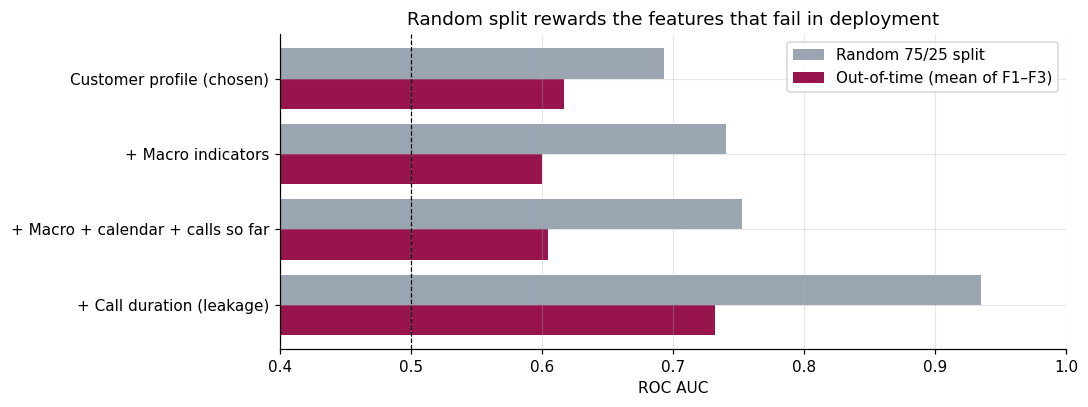

In [11]:
fig, ax = plt.subplots(figsize=(10, 3.8))
y = np.arange(len(trap))
ax.barh(y - 0.2, trap['random_split_auc'], height=0.4, color=GREY, label='Random 75/25 split')
ax.barh(y + 0.2, trap['out_of_time_auc'], height=0.4, color=BRAND, label='Out-of-time (mean of F1–F3)')
ax.axvline(0.5, color='black', lw=0.8, ls='--')
ax.set_yticks(y)
ax.set_yticklabels(trap.index)
ax.invert_yaxis()
ax.set_xlim(0.4, 1.0)
ax.set_xlabel('ROC AUC')
ax.set_title('Random split rewards the features that fail in deployment')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

**Reading the table**
- **Every model looks better on a random split than it really is.** The overstatement is smallest for the clean customer model and roughly doubles once macro and calendar features are added.
- **On a random split, macro and calendar features appear to add ~0.05–0.06 AUC. Out-of-time they add nothing** — and the kitchen-sink model's worst fold drops to ≈0.53, barely better than a coin toss.
- Why: in training these features mostly encode *time* ("Euribor fell, conversion rose"). A random split puts rows from the same weeks on both sides, so the model just recognises the week. On a genuinely new period it extrapolates the trend instead of ranking customers.
- **Duration** still scores well out-of-time because it *is* the outcome in disguise (only engaged customers stay on the line). Its problem isn't generalisation, it's availability: it doesn't exist until the call is over.

Decision: the targeting model uses **customer profile features only**. Macro context belongs in a separate volume/timing forecast, not in the ranking score (revisited in §7.1).

## 6. Model selection: logistic regression vs. gradient boosting
Three metrics per fold:
- **Pooled AUC** — ranking across the whole test window.
- **Within-month AUC** — ranking inside each month, averaged. This is the decision that actually matters: which customers in *this* wave to call first.
- **Top-decile lift** — conversion of the top 10% scored ÷ average conversion.

Selection rule, fixed before looking at results: take logistic regression unless gradient boosting wins mean within-month AUC on F1–F3 by more than 0.01. Logistic regression is easier to explain, audit and monitor, which counts in a bank.

In [12]:
cols = CAT_FEATURES + NUM_FEATURES
sel_rows, cold_start_scores = [], None
for fold in FOLDS:
    tr, te = fold_split(DEV, fold)
    for mname, mk in [('Logistic regression', lr_model), ('Gradient boosting', gb_model)]:
        m = make_pipeline(mk(), CAT_FEATURES, NUM_FEATURES).fit(tr[cols], tr['target'])
        scored = te.assign(score=m.predict_proba(te[cols])[:, 1])
        sel_rows.append({'fold': fold, 'model': mname, 'train_n': len(tr), 'test_n': len(te),
                         'test_conv': te['target'].mean(),
                         'pooled_auc': roc_auc_score(scored['target'], scored['score']),
                         'within_month_auc': within_month_auc(scored),
                         'top_decile_lift': top_decile_lift(scored['target'], scored['score'])})
selection = pd.DataFrame(sel_rows)
print(selection.round(3).to_string(index=False), '\n')

summary_sel = selection[selection['fold'].isin(OOT_FOLDS)].groupby('model')[['pooled_auc', 'within_month_auc', 'top_decile_lift']].mean()
print('Mean over F1–F3:')
print(summary_sel.round(3), '\n')

gb_gain = summary_sel.loc['Gradient boosting', 'within_month_auc'] - summary_sel.loc['Logistic regression', 'within_month_auc']
CHOSEN = 'Gradient boosting' if gb_gain > 0.01 else 'Logistic regression'
chosen_model = gb_model if CHOSEN == 'Gradient boosting' else lr_model
print(f'GB advantage in within-month AUC: {gb_gain:+.3f}  ->  chosen model: {CHOSEN}')

           fold               model  train_n  test_n  test_conv  pooled_auc  within_month_auc  top_decile_lift
F0 (cold start) Logistic regression    23997    6433      0.125       0.467             0.463            0.736
F0 (cold start)   Gradient boosting    23997    6433      0.125       0.456             0.470            0.711
             F1 Logistic regression    30430    6509      0.121       0.635             0.600            2.271
             F1   Gradient boosting    30430    6509      0.121       0.626             0.588            1.878
             F2 Logistic regression    36939    1215      0.359       0.591             0.593            1.622
             F2   Gradient boosting    36939    1215      0.359       0.599             0.600            1.553
             F3 Logistic regression    38154     976      0.447       0.625             0.621            1.622
             F3   Gradient boosting    38154     976      0.447       0.630             0.628            1.576 


**Takeaways**
- The two models are effectively tied on F1–F3, so the simpler model wins under the pre-set rule. The extra flexibility of boosting doesn't pay when the signal is a handful of strong categorical effects.
- **F0 (cold start) scores below 0.5 for both models.** Trained only on the signal-free first wave, the model learns noise (e.g. a channel pattern that reversed by November 2008). This confirms §4.1: don't deploy before response history exists.

## 7. Final model on the untouched 2010 holdout
Train on all development data (May 2008 – Dec 2009), score every 2010 customer once.

In [13]:
final_model = make_pipeline(chosen_model(), CAT_FEATURES, NUM_FEATURES).fit(DEV[cols], DEV['target'])
HOLDOUT['score'] = final_model.predict_proba(HOLDOUT[cols])[:, 1]

holdout_auc = roc_auc_score(HOLDOUT['target'], HOLDOUT['score'])
holdout_wm_auc = within_month_auc(HOLDOUT)
# Same model, evaluated the "tutorial" way, for contrast
m_rand = make_pipeline(chosen_model(), CAT_FEATURES, NUM_FEATURES).fit(tr_r[cols], tr_r['target'])
random_auc_same_model = roc_auc_score(te_r['target'], m_rand.predict_proba(te_r[cols])[:, 1])

print(f'Holdout 2010: {len(HOLDOUT):,} customers, conversion {HOLDOUT["target"].mean():.1%}')
print(f'  AUC (pooled):        {holdout_auc:.3f}')
print(f'  AUC (within-month):  {holdout_wm_auc:.3f}')
print(f'  Same model on a random split of 2008–09 data: {random_auc_same_model:.3f}  <- the number most notebooks would report')


def gains_table(frame, score_col='score', n_bins=10):
    f = frame.copy()
    f['decile'] = pd.qcut(f[score_col].rank(method='first', ascending=False), n_bins, labels=range(1, n_bins + 1))
    g = f.groupby('decile', observed=True).agg(customers=('target', 'size'), subscribers=('target', 'sum'),
                                               min_score=(score_col, 'min'), max_score=(score_col, 'max'))
    g['conversion'] = g['subscribers'] / g['customers']
    g['lift'] = g['conversion'] / f['target'].mean()
    g['cum_pct_customers'] = g['customers'].cumsum() / g['customers'].sum()
    g['cum_pct_subscribers'] = g['subscribers'].cumsum() / g['subscribers'].sum()
    return g, f['decile']


gains, HOLDOUT['decile'] = gains_table(HOLDOUT)
gains.round(3)

Holdout 2010: 2,058 customers, conversion 52.1%
  AUC (pooled):        0.679
  AUC (within-month):  0.678
  Same model on a random split of 2008–09 data: 0.693  <- the number most notebooks would report


,customers,subscribers,min_score,max_score,conversion,lift,cum_pct_customers,cum_pct_subscribers
decile,,,,,,,,
1,206,163,0.713,0.929,0.791,1.518,0.1,0.152
2,206,156,0.567,0.712,0.757,1.452,0.2,0.297
3,206,146,0.439,0.567,0.709,1.359,0.3,0.433
4,205,110,0.311,0.438,0.537,1.029,0.4,0.536
5,206,83,0.187,0.311,0.403,0.773,0.5,0.613
6,206,92,0.136,0.186,0.447,0.857,0.6,0.699
7,205,81,0.114,0.136,0.395,0.758,0.7,0.774
8,206,115,0.100,0.114,0.558,1.071,0.8,0.882
9,206,87,0.065,0.099,0.422,0.810,0.9,0.963


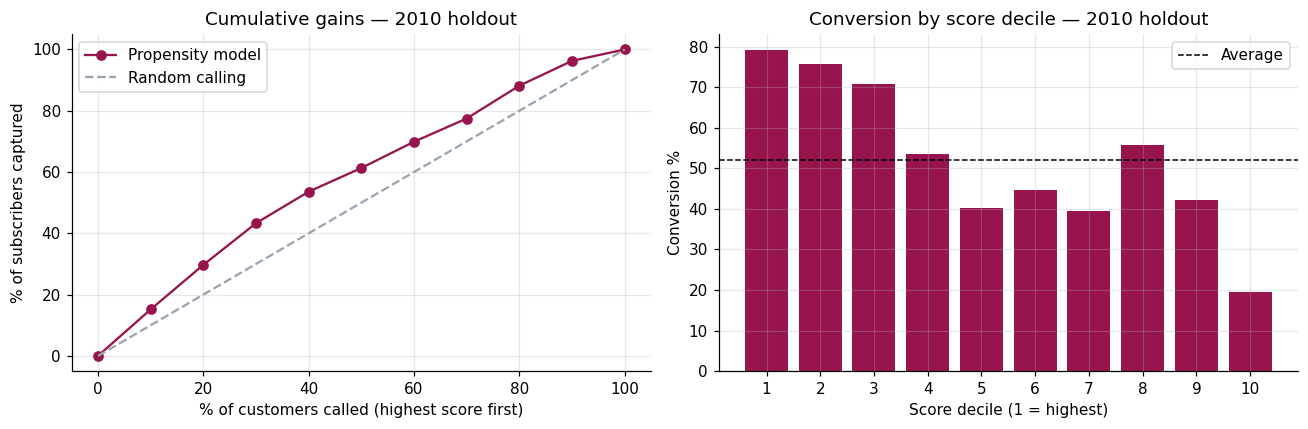

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.r_[0, gains['cum_pct_customers'].values] * 100
axes[0].plot(x, np.r_[0, gains['cum_pct_subscribers'].values] * 100, marker='o', color=BRAND, label='Propensity model')
axes[0].plot([0, 100], [0, 100], ls='--', color=GREY, label='Random calling')
axes[0].set_xlabel('% of customers called (highest score first)')
axes[0].set_ylabel('% of subscribers captured')
axes[0].set_title('Cumulative gains — 2010 holdout')
axes[0].legend()
axes[1].bar(gains.index.astype(str), gains['conversion'] * 100, color=BRAND)
axes[1].axhline(HOLDOUT['target'].mean() * 100, color='black', ls='--', lw=1, label='Average')
axes[1].set_xlabel('Score decile (1 = highest)')
axes[1].set_ylabel('Conversion %')
axes[1].set_title('Conversion by score decile — 2010 holdout')
axes[1].legend()
plt.tight_layout()
plt.show()

The holdout AUC (≈0.68) sits a little above the development folds (0.59–0.64) and below the random-split figure. The business gradient is real but uneven: **the top three deciles convert at ~71–79% against a 52% average and the bottom decile at ~19%, while deciles 4–9 are fairly flat.** The model is good at spotting the best and worst customers and weak at ordering the middle — useful to know when deciding how deep into the list to call. In a 52%-conversion year that gradient matters most when call capacity is limited (§11).

### 7.1 Post-hoc check — other feature sets on the holdout (not used for selection)
Reported for transparency after the model was locked. Choosing based on this table would turn the holdout into one more training signal.

In [15]:
posthoc = []
for name, (cats, nums) in FEATURE_SETS.items():
    c = cats + nums
    m = make_pipeline(lr_model(), cats, nums).fit(DEV[c], DEV['target'])
    h = HOLDOUT[['ym', 'target']].assign(score=m.predict_proba(HOLDOUT[c])[:, 1])
    posthoc.append({'feature_set': name, 'dev_out_of_time_auc': trap.loc[name, 'out_of_time_auc'],
                    'holdout_2010_auc': roc_auc_score(h['target'], h['score']),
                    'holdout_within_month_auc': within_month_auc(h)})
pd.DataFrame(posthoc).set_index('feature_set').round(3)

,dev_out_of_time_auc,holdout_2010_auc,holdout_within_month_auc
feature_set,,,
Customer profile (chosen),0.617,0.679,0.678
+ Macro indicators,0.600,0.709,0.711
+ Macro + calendar + calls so far,0.605,0.592,0.719
+ Call duration (leakage),0.732,0.691,0.820


**An honest wrinkle:** macro indicators score *higher* on 2010 (≈0.71 vs ≈0.68) after scoring *lower* on all three development folds. Their contribution flips with the period, which is the instability §5 warned about. Because they are identical for everyone called on the same day, any gain inside a month comes from day-to-day variation — *which day* the call happened, not *which customer* was called. That is worth modelling, but as a separate timing/volume model re-tested as new periods arrive, not baked into the customer score. The calendar-heavy model shows the other failure: strong within-month (≈0.72), poor pooled (≈0.59), because 2008–09 month labels mis-rank customers across 2010 months.

## 8. What drives propensity? (explanatory model with month fixed effects)
The targeting model is built for ranking. To explain *why*, fit a separate logistic regression with **month fixed effects** — one dummy per campaign month. Each customer effect is then measured among people called in the same month, so the time drift found in §4 can't masquerade as a customer effect. Coefficients are reported as odds ratios with 95% confidence intervals.

In [16]:
d = df.copy()
d['ym_s'] = d['ym'].astype(str)
formula = ("target ~ C(job, Treatment('admin.')) + C(marital, Treatment('married'))"
           " + C(education, Treatment('university.degree')) + C(default, Treatment('no'))"
           " + C(products, Treatment('no/no')) + C(contact, Treatment('cellular'))"
           " + C(poutcome, Treatment('nonexistent')) + C(age_band, Treatment('31-40')) + previous + C(ym_s)")
driver_fit = smf.logit(formula, data=d).fit(disp=0, maxiter=300)
ci = driver_fit.conf_int()
drivers = pd.DataFrame({'odds_ratio': np.exp(driver_fit.params), 'ci_low': np.exp(ci[0]),
                        'ci_high': np.exp(ci[1]), 'p_value': driver_fit.pvalues})
drivers = drivers[~drivers.index.str.contains('ym_s|Intercept')]
drivers.index = (drivers.index.str.replace(r"C\((\w+), Treatment\('[^']*'\)\)\[T\.(.+)\]", r'\1 = \2', regex=True))
print(f'Converged: {driver_fit.mle_retvals["converged"]} | pseudo R²: {driver_fit.prsquared:.3f}')
print('Baselines: job=admin., marital=married, education=university.degree, default=no, products=no/no,')
print('           contact=cellular, poutcome=nonexistent, age_band=31-40\n')
drivers.sort_values('odds_ratio', ascending=False).round(3)

Converged: True | pseudo R²: 0.219
Baselines: job=admin., marital=married, education=university.degree, default=no, products=no/no,
           contact=cellular, poutcome=nonexistent, age_band=31-40



,odds_ratio,ci_low,ci_high,p_value
poutcome = success,3.383,2.717,4.212,0.000
marital = unknown,1.319,0.643,2.706,0.449
age_band = 60+,1.283,1.027,1.604,0.028
age_band = <=25,1.223,1.029,1.454,0.022
age_band = 26-30,1.104,0.991,1.231,0.073
job = student,1.104,0.895,1.362,0.357
job = retired,1.101,0.897,1.351,0.359
age_band = 51-60,1.095,0.974,1.231,0.129
education = basic.6y,1.064,0.880,1.287,0.521
previous,1.052,0.929,1.191,0.423


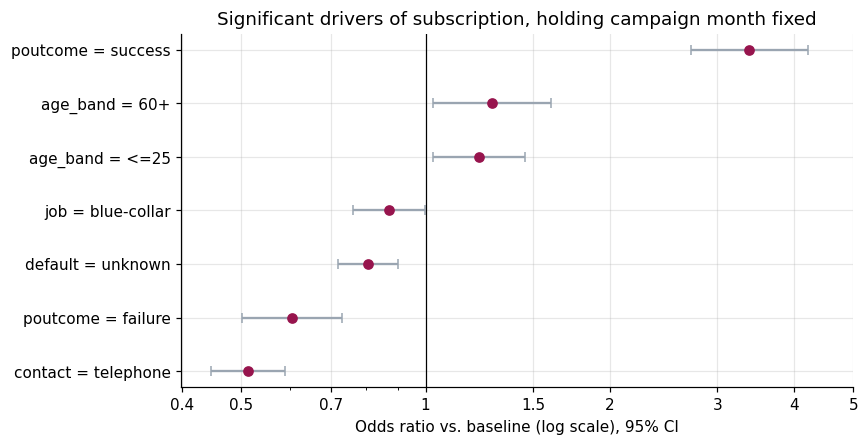

In [17]:
sig = drivers[drivers['p_value'] < 0.05].sort_values('odds_ratio')
fig, ax = plt.subplots(figsize=(8, 0.45 * len(sig) + 1))
ax.errorbar(sig['odds_ratio'], range(len(sig)),
            xerr=[sig['odds_ratio'] - sig['ci_low'], sig['ci_high'] - sig['odds_ratio']],
            fmt='o', color=BRAND, ecolor=GREY, capsize=3)
ax.axvline(1, color='black', lw=0.8)
ax.set_xscale('log')
ticks = [0.4, 0.5, 0.7, 1, 1.5, 2, 3, 4, 5]
ax.set_xticks(ticks)
ax.set_xticklabels([f'{t:g}' for t in ticks])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_yticks(range(len(sig)))
ax.set_yticklabels(sig.index)
ax.set_xlabel('Odds ratio vs. baseline (log scale), 95% CI')
ax.set_title('Significant drivers of subscription, holding campaign month fixed')
plt.tight_layout()
plt.show()

**Driver story (all comparisons within the same campaign month)**
- **Past campaign success** multiplies the odds of subscribing roughly 3×; a past *failure* lowers them compared with never having been contacted. Previous responders are the single best list to call.
- **Landline contacts have about half the odds** of mobile contacts — the channel finding taken further in §12.
- **`default = unknown`** lowers odds by about a fifth; **age ≤25 and 60+** raise them by about a fifth or more.
- **Most job, education, marital and product-holding effects are not significant** once timing is controlled. The large raw gaps in §3 were mostly a timing artefact — a Simpson's-paradox pattern worth flagging to any business team slicing raw campaign reports.

## 9. Calibration under drift
AUC only measures ranking. Any rupee calculation (expected value per call) needs the probability *level* to be right too. A model trained on 2008–09 (≈9% average conversion) will underestimate a 52% year.

Fix: recalibrate on the most recent labelled quarter (Oct–Dec 2009), without retraining. Two options, both keep the ranking unchanged:
1. **Level shift** — move every score by the same amount on the log-odds scale so the average prediction matches recent conversion.
2. **Platt scaling** — fit a one-variable logistic regression on the model's log-odds, which adjusts the level *and* the spread.

Recalibration window Oct–Dec 2009: 976 customers, conversion 44.7%
  level shift = +1.10 log-odds | Platt slope = 0.45, intercept = +0.36

Holdout actual conversion: 52.1%
  Raw model      mean predicted 30.9% | Brier 0.278 | AUC 0.679
  Level shift    mean predicted 49.4% | Brier 0.237 | AUC 0.679
  Platt scaling  mean predicted 47.2% | Brier 0.226 | AUC 0.679


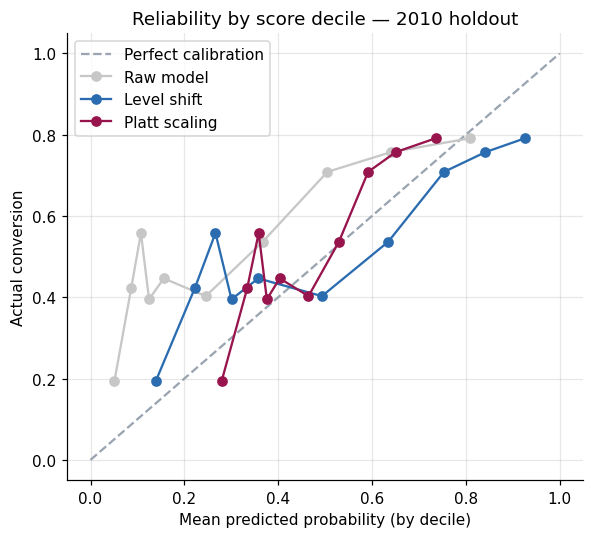

,actual,raw,level_shift,platt
decile,,,,
1,0.791,0.809,0.926,0.736
2,0.757,0.641,0.842,0.651
3,0.709,0.505,0.754,0.592
4,0.537,0.367,0.635,0.530
5,0.403,0.246,0.493,0.465
6,0.447,0.156,0.358,0.403
7,0.395,0.125,0.301,0.376
8,0.558,0.108,0.266,0.359
9,0.422,0.087,0.222,0.334


In [18]:
def intercept_shift(p, target_rate):
    """Log-odds shift that makes mean(p_adjusted) equal target_rate. Preserves ranking."""
    z = logit(np.clip(p, 1e-6, 1 - 1e-6))
    return brentq(lambda delta: expit(z + delta).mean() - target_rate, -15, 15)


def to_logodds(p):
    return logit(np.clip(np.asarray(p), 1e-6, 1 - 1e-6)).reshape(-1, 1)


recent = DEV[DEV['ym'] >= 200910]
recent_scores = final_model.predict_proba(recent[cols])[:, 1]

# Option 1: level shift
delta = intercept_shift(recent_scores, recent['target'].mean())
HOLDOUT['score_shift'] = expit(to_logodds(HOLDOUT['score']).ravel() + delta)

# Option 2: Platt scaling (slope + intercept on the log-odds)
platt = LogisticRegression(C=1e6).fit(to_logodds(recent_scores), recent['target'])
HOLDOUT['score_cal'] = platt.predict_proba(to_logodds(HOLDOUT['score']))[:, 1]

print(f"Recalibration window Oct–Dec 2009: {len(recent)} customers, conversion {recent['target'].mean():.1%}")
print(f"  level shift = {delta:+.2f} log-odds | Platt slope = {platt.coef_[0][0]:.2f}, intercept = {platt.intercept_[0]:+.2f}\n")
print(f"Holdout actual conversion: {HOLDOUT['target'].mean():.1%}")
for label, col in [('Raw model', 'score'), ('Level shift', 'score_shift'), ('Platt scaling', 'score_cal')]:
    print(f"  {label:<14} mean predicted {HOLDOUT[col].mean():.1%} | Brier {brier_score_loss(HOLDOUT['target'], HOLDOUT[col]):.3f} "
          f"| AUC {roc_auc_score(HOLDOUT['target'], HOLDOUT[col]):.3f}")

calib = (HOLDOUT.groupby('decile', observed=True)
                .agg(actual=('target', 'mean'), raw=('score', 'mean'), level_shift=('score_shift', 'mean'),
                     platt=('score_cal', 'mean')))

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], ls='--', color=GREY, label='Perfect calibration')
ax.plot(calib['raw'], calib['actual'], marker='o', color='#c7c7c7', label='Raw model')
ax.plot(calib['level_shift'], calib['actual'], marker='o', color='#2b6cb0', label='Level shift')
ax.plot(calib['platt'], calib['actual'], marker='o', color=BRAND, label='Platt scaling')
ax.set_xlabel('Mean predicted probability (by decile)')
ax.set_ylabel('Actual conversion')
ax.set_title('Reliability by score decile — 2010 holdout')
ax.legend()
plt.tight_layout()
plt.show()
calib.round(3)

- The raw model under-predicts badly (~31% vs 52%) — it learned a ~9% world.
- The level shift fixes the average but over-predicts the top deciles (~90%+ predicted vs ~79% actual).
- Platt scaling's slope (≈0.45, well below 1) says the 2008–09 model is **over-confident about how different customers are** in the new regime. Shrinking the spread brings the deciles closest to the diagonal and gives the best Brier score; it's the version carried forward (`score_cal`).

Ranking survives drift; probability levels and spreads don't. Monitoring should track the two separately: **AUC** (is the ranking still valid — retrain if it decays) and **calibration** (is the level right — recalibrate monthly from recent results, which is cheap).

### 9.1 F1 score — reported, but not the headline metric
F1 needs a yes/no cut-off. It is reported here four ways on the 2010 holdout, including the trivial "call everyone" rule as a baseline, and then checked across evaluation windows with different base rates.

In [19]:
def best_f1_threshold(y, s):
    p, r, t = precision_recall_curve(y, s)
    f = 2 * p * r / np.clip(p + r, 1e-12, None)
    i = int(np.nanargmax(f[:-1]))
    return t[i], f[i]


y_h = HOLDOUT['target'].values
recent_cal = platt.predict_proba(to_logodds(recent_scores))[:, 1]
thr_dev, _ = best_f1_threshold(recent['target'].values, recent_cal)          # chosen on Oct–Dec 2009
thr_oracle, F1_MAX = best_f1_threshold(y_h, HOLDOUT['score_cal'].values)   # chosen on 2010 itself (optimistic)

rules = [('Call everyone (no model)', np.ones_like(y_h, dtype=bool)),
         ('Cut-off 0.50 on recalibrated score', HOLDOUT['score_cal'].values >= 0.5),
         (f'Cut-off tuned on Oct–Dec 2009 ({thr_dev:.2f})', HOLDOUT['score_cal'].values >= thr_dev),
         (f'Best cut-off chosen on 2010 itself ({thr_oracle:.2f}) — optimistic', HOLDOUT['score_cal'].values >= thr_oracle)]
f1_table = pd.DataFrame([{'rule': name, 'share_flagged': pred.mean(), 'precision': precision_score(y_h, pred),
                          'recall': recall_score(y_h, pred), 'f1': f1_score(y_h, pred)} for name, pred in rules]).set_index('rule')
F1_BASELINE = f1_table.iloc[0]['f1']
F1_DEV_TUNED = f1_table.iloc[2]['f1']
print(f'2010 holdout, base rate {y_h.mean():.1%}')
print(f1_table.round(3), '\n')

# Same model specification, different evaluation windows: F1 follows the base rate
windows = [('Random 25% of 2008–09', tr_r, te_r)] + [(f, *fold_split(DEV, f)) for f in OOT_FOLDS] + [('2010 holdout', DEV, HOLDOUT)]
f1_by_window = []
for name, tr, te in windows:
    m = make_pipeline(chosen_model(), CAT_FEATURES, NUM_FEATURES).fit(tr[cols], tr['target'])
    s_te = m.predict_proba(te[cols])[:, 1]
    b = te['target'].mean()
    f1_by_window.append({'window': name, 'base_rate': b, 'call_everyone_f1': 2 * b / (1 + b),
                         'model_best_f1': best_f1_threshold(te['target'].values, s_te)[1],
                         'model_auc': roc_auc_score(te['target'], s_te)})
f1_by_window = pd.DataFrame(f1_by_window).set_index('window')
f1_by_window.round(3)

2010 holdout, base rate 52.1%
                                                    share_flagged  precision  recall     f1
rule                                                                                       
Call everyone (no model)                                    1.000      0.521   1.000  0.685
Cut-off 0.50 on recalibrated score                          0.406      0.695   0.541  0.609
Cut-off tuned on Oct–Dec 2009 (0.28)                        0.950      0.537   0.978  0.693
Best cut-off chosen on 2010 itself (0.32) — opt...          0.875      0.569   0.955  0.713 



,base_rate,call_everyone_f1,model_best_f1,model_auc
window,,,,
Random 25% of 2008–09,0.091,0.167,0.283,0.693
F1,0.121,0.216,0.277,0.635
F2,0.359,0.528,0.531,0.591
F3,0.447,0.618,0.624,0.625
2010 holdout,0.521,0.685,0.713,0.679


**Why F1 isn't the headline here**
- At a 52% base rate, the F1-maximising cut-off flags almost everyone. The best achievable holdout F1 (≈0.71, and only with a cut-off picked on the holdout itself) is barely above the ≈0.69 you get by calling everyone; with a cut-off picked on 2009 data it is ≈0.69 — no better than having no model.
- F1 follows the base rate rather than model quality: the same specification scores ≈0.28 at 9% conversion and ≈0.62 at 45%, while AUC stays in a narrow band. F1 can't compare periods, and under drift a fixed cut-off stops meaning anything.
- The business decision is *whom to call first* under a cost or capacity limit — a ranking question. That's what AUC (or Gini = 2·AUC − 1, the usual bank scorecard metric), decile lift and the profit curve measure.

### 9.2 Can F1 and precision be pushed higher? A systematic attempt
Five legitimate changes, each aimed at precision or F1, plus one invalid reference:
- **Interactions** (past outcome × channel, age × channel) and **recency of the last contact** (`pdays` bucketed — 0–3, 4–6, 7+ days, never).
- **Recency-weighted training** — under drift, recent months should count more. Each row is weighted 0.5^(months old ÷ 6).
- **Gradient boosting** with the same additions.
- **Macro indicators**, recency-weighted.
- *Invalid reference:* call duration, to show what leakage would do.

Every candidate uses the same honest protocol: recalibrate (Platt) and pick the F1 cut-off on the last three campaign months of its own training data, then apply that cut-off unchanged. Three test beds: the development folds F1–F3, the 2010 holdout, and a monthly walk-forward from Mar-09 to Nov-10 (13,498 customers, retrained every month). The walk-forward is the largest and most varied test, so it carries the most weight.

In [20]:
dfx = df.copy()
dfx['pout_contact'] = dfx['poutcome'] + '|' + dfx['contact']
dfx['age_contact'] = dfx['age_band'] + '|' + dfx['contact']
dfx['pdays_bucket'] = np.select([dfx['pdays'] == 999, dfx['pdays'] <= 3, dfx['pdays'] <= 6], ['never', '0-3', '4-6'], '7+')
dfx['month_index'] = (dfx['year'] - 2008) * 12 + dfx['month_num']
EXTRA = ['pout_contact', 'age_contact', 'pdays_bucket']

CANDIDATES = {
    'Current model (LR, customer features)': ('lr', CAT_FEATURES, NUM_FEATURES, None),
    '+ interactions & last-contact recency': ('lr', CAT_FEATURES + EXTRA, NUM_FEATURES, None),
    '+ recency-weighted training': ('lr', CAT_FEATURES, NUM_FEATURES, 6),
    '+ both': ('lr', CAT_FEATURES + EXTRA, NUM_FEATURES, 6),
    'Gradient boosting + last-contact recency, weighted': ('gb', CAT_FEATURES + ['pdays_bucket'], NUM_FEATURES, 6),
    '+ macro indicators, weighted': ('lr', CAT_FEATURES, NUM_FEATURES + MACRO, 6),
    'INVALID: + call duration (leakage)': ('lr', CAT_FEATURES, NUM_FEATURES + ['duration'], None),
}


def fit_candidate(cfg, train):
    """Fit, then recalibrate and choose the F1 cut-off on the last 3 campaign months of the training data."""
    kind, cats, nums, half_life = cfg
    feats = cats + nums
    model = make_pipeline(lr_model() if kind == 'lr' else gb_model(), cats, nums)
    weights = None if half_life is None else 0.5 ** ((train['month_index'].max() - train['month_index']) / half_life)
    model.fit(train[feats], train['target'], model__sample_weight=weights)
    r = train[train['ym'].isin(sorted(train['ym'].unique())[-3:])]
    s_r = model.predict_proba(r[feats])[:, 1]
    cal = LogisticRegression(C=1e6).fit(to_logodds(s_r), r['target'])
    thr, _ = best_f1_threshold(r['target'].values, cal.predict_proba(to_logodds(s_r))[:, 1])

    def predict(test):
        s = model.predict_proba(test[feats])[:, 1]
        return s, cal.predict_proba(to_logodds(s))[:, 1] >= thr
    return predict


def scores(y, s, pred):
    return {'f1': f1_score(y, pred), 'precision': precision_score(y, pred), 'recall': recall_score(y, pred),
            'auc': roc_auc_score(y, s)}


DEVX, HOLDX = dfx[dfx['ym'] <= 200912], dfx[dfx['ym'] >= 201001]
WF_MONTHS = [m for m in sorted(dfx['ym'].unique()) if m >= 200903]
attempt = []
for name, cfg in CANDIDATES.items():
    fold_res = []
    for f in OOT_FOLDS:
        tr, te = fold_split(DEVX, f)
        s, pred = fit_candidate(cfg, tr)(te)
        fold_res.append(scores(te['target'], s, pred))
    s, pred = fit_candidate(cfg, DEVX)(HOLDX)
    ho = scores(HOLDX['target'], s, pred)
    ys, preds = [], []
    for M in WF_MONTHS:
        te = dfx[dfx['ym'] == M]
        _, pred = fit_candidate(cfg, dfx[dfx['ym'] < M])(te)
        ys.append(te['target'].values)
        preds.append(pred)
    y_wf, p_wf = np.concatenate(ys), np.concatenate(preds)
    attempt.append({'candidate': name,
                    'dev_f1': np.mean([r['f1'] for r in fold_res]), 'dev_precision': np.mean([r['precision'] for r in fold_res]),
                    'holdout_f1': ho['f1'], 'holdout_precision': ho['precision'], 'holdout_auc': ho['auc'],
                    'walkforward_f1': f1_score(y_wf, p_wf), 'walkforward_precision': precision_score(y_wf, p_wf)})

b_ho, b_wf = HOLDX['target'].mean(), dfx[dfx['ym'].isin(WF_MONTHS)]['target'].mean()
attempt.append({'candidate': 'Call everyone (no model)', 'holdout_f1': 2 * b_ho / (1 + b_ho), 'holdout_precision': b_ho,
                'walkforward_f1': 2 * b_wf / (1 + b_wf), 'walkforward_precision': b_wf})
attempt = pd.DataFrame(attempt).set_index('candidate')
current = attempt.iloc[0]
attempt['walkforward_f1_vs_current'] = attempt['walkforward_f1'] - current['walkforward_f1']
attempt.round(3)

,dev_f1,dev_precision,holdout_f1,holdout_precision,holdout_auc,walkforward_f1,walkforward_precision,walkforward_f1_vs_current
candidate,,,,,,,,
"Current model (LR, customer features)",0.451,0.349,0.693,0.537,0.679,0.492,0.376,0.000
+ interactions & last-contact recency,0.451,0.355,0.699,0.545,0.686,0.488,0.375,-0.004
+ recency-weighted training,0.454,0.340,0.706,0.564,0.685,0.473,0.354,-0.019
+ both,0.456,0.349,0.710,0.568,0.694,0.481,0.360,-0.011
"Gradient boosting + last-contact recency, weighted",0.453,0.355,0.712,0.582,0.698,0.469,0.364,-0.023
"+ macro indicators, weighted",0.405,0.361,0.698,0.605,0.708,0.458,0.340,-0.034
INVALID: + call duration (leakage),0.561,0.470,0.743,0.629,0.766,0.597,0.507,0.106
Call everyone (no model),NaN,NaN,0.685,0.521,NaN,0.393,0.245,-0.099


**Precision is a choice of operating point, not a model property.** Below, the current model flags only the top X% of the 2010 holdout list. F0.5 is the F-score that weights precision twice as heavily as recall — the right yardstick when wasted calls are the main cost.

In [21]:
order = np.argsort(-HOLDOUT['score'].values)
op_rows = []
for share in [0.10, 0.20, 0.30, 0.50, 0.70, 0.90, 1.00]:
    pred = np.zeros(len(order), dtype=bool)
    pred[order[:int(round(len(order) * share))]] = True
    op_rows.append({'flag_top_%': int(share * 100), 'precision': precision_score(y_h, pred),
                    'recall': recall_score(y_h, pred), 'f1': f1_score(y_h, pred),
                    'f0.5': fbeta_score(y_h, pred, beta=0.5)})
operating_points = pd.DataFrame(op_rows).set_index('flag_top_%')
operating_points.round(3)

,precision,recall,f1,f0.5
flag_top_%,,,,
10,0.791,0.152,0.255,0.430
20,0.774,0.297,0.430,0.586
30,0.752,0.432,0.549,0.655
50,0.639,0.613,0.626,0.634
70,0.577,0.775,0.662,0.608
90,0.558,0.963,0.706,0.609
100,0.521,1.000,0.685,0.577


**Verdict: the current model is already at the ceiling this data allows.**
- None of the five legitimate changes improves F1 or precision on the 13,498-customer walk-forward; all land at or below the current model. The small holdout gains some of them show (≈+0.01–0.02 F1 on 2,058 customers) don't survive the larger test, so they're noise, and adopting them would be fitting to the holdout.
- Even the invalid duration model only lifts holdout F1 to ≈0.74. At a 52% base rate, F1 is pinned between ≈0.69 (call everyone) and the low 0.70s for any realistic model.
- To get higher precision, use a stricter cut-off and accept lower recall: flagging the top 30% gives ≈75% precision against a 52% base rate. If precision is what the business values, pick the cut-off by F0.5 or by call-centre capacity, not by F1.
- Real gains would need new information, not more tuning — account balances, product holdings, transaction history, or a randomised control group for uplift modelling.

## 10. Deployment simulation: monthly walk-forward scoring (model monitoring view)
This mimics production. For every month from Nov-08 onward: retrain on all earlier months, score this month's call list, record the result. Nothing from the scored month is used. The output doubles as the monitoring dashboard a BIU team would track.

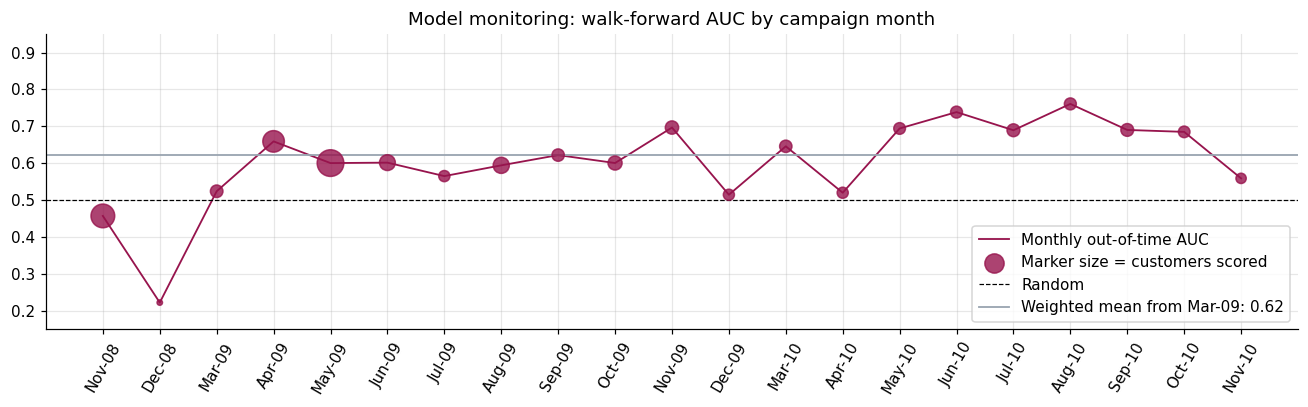

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
ym,200811,200812,200903,200904,200905,200906,200907,200908,200909,200910,200911,200912,201003,201004,201005,201006,201007,201008,201009,201010,201011
period,Nov-08,Dec-08,Mar-09,Apr-09,May-09,Jun-09,Jul-09,Aug-09,Sep-09,Oct-09,Nov-09,Dec-09,Mar-10,Apr-10,May-10,Jun-10,Jul-10,Aug-10,Sep-10,Oct-10,Nov-10
customers,3616,10,282,2458,5794,715,178,770,267,447,357,172,264,174,212,229,311,233,303,204,128
conversion,0.053,0.1,0.447,0.18,0.09,0.369,0.371,0.343,0.397,0.403,0.471,0.512,0.568,0.557,0.575,0.467,0.566,0.515,0.495,0.456,0.453
auc,0.457,0.222,0.524,0.659,0.6,0.602,0.565,0.594,0.622,0.601,0.697,0.515,0.646,0.52,0.694,0.739,0.689,0.761,0.69,0.685,0.559


In [22]:
wf_parts, wf_monitor = [], []
for M in sorted(df['ym'].unique()):
    if M < 200811:
        continue
    train, test = df[df['ym'] < M], df[df['ym'] == M]
    m = make_pipeline(chosen_model(), CAT_FEATURES, NUM_FEATURES).fit(train[cols], train['target'])
    s = m.predict_proba(test[cols])[:, 1]
    part = test[['ym', 'period', 'target', 'campaign', 'contact']].assign(score=s)
    part['pct_rank'] = part['score'].rank(pct=True, method='first')     # 1.0 = best customer in this month's list
    part['decile'] = np.ceil((1 - part['pct_rank']) * 10).clip(1, 10).astype(int)
    wf_parts.append(part)
    wf_monitor.append({'ym': M, 'period': test['period'].iloc[0], 'customers': len(test),
                       'conversion': test['target'].mean(),
                       'auc': roc_auc_score(test['target'], s) if test['target'].nunique() == 2 else np.nan})
wf = pd.concat(wf_parts)
wf_monitor = pd.DataFrame(wf_monitor)
reliable = wf_monitor[(wf_monitor['customers'] >= 100) & (wf_monitor['ym'] >= 200903)]
wf_mean_auc = np.average(reliable['auc'], weights=reliable['customers'])

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(wf_monitor['period'], wf_monitor['auc'], color=BRAND, lw=1.2, label='Monthly out-of-time AUC')
ax.scatter(wf_monitor['period'], wf_monitor['auc'], s=np.sqrt(wf_monitor['customers']) * 4, color=BRAND,
           alpha=0.8, zorder=3, label='Marker size = customers scored')
ax.axhline(0.5, color='black', lw=0.8, ls='--', label='Random')
ax.axhline(wf_mean_auc, color=GREY, lw=1.2, label=f'Weighted mean from Mar-09: {wf_mean_auc:.2f}')
ax.set_ylim(0.15, 0.95)
ax.tick_params(axis='x', rotation=60)
ax.set_title('Model monitoring: walk-forward AUC by campaign month')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()
wf_monitor.round(3).T

From March 2009 the model beats random in every month, ranging from ~0.52 to ~0.76 (customer-weighted mean ≈0.62), and it improves through 2010 as response history accumulates. The weak points are informative: **Nov-08** (cold start — trained only on the signal-free first wave), and small months (Dec-08 with 10 customers; Dec-09 and Apr-10 with under 180), where one or two calls swing the AUC. In production: alert when AUC drops below ~0.55 on a month with enough volume (say 300+ customers) or trends down for several months, and don't over-react to small months.

## 11. Valuation: what is a call worth?

### Assumptions (illustrative — replace with the bank's actual numbers)
The dataset has no rupee values, so the economics are explicit parameters. Change them and re-run; every number below updates.
- **Value of one new term deposit** = average ticket × annual net spread (the funds-transfer-pricing margin the bank earns on deposit funding) × tenure.
  Illustrative: ₹1,00,000 × 1.5% × 1 year = **₹1,500**.
- **Cost of one outbound call attempt** (agent time, telephony, overhead): **₹50**.
- Customer-level profit = subscribed × value − calls made × cost per call.

In [23]:
AVG_TICKET = 100_000      # ₹ per term deposit
NET_SPREAD = 0.015        # annual margin earned on the deposit
TENURE_YEARS = 1
COST_PER_CALL = 50        # ₹ per call attempt
VALUE_PER_SUB = AVG_TICKET * NET_SPREAD * TENURE_YEARS
BREAKEVEN_PER_CALL = COST_PER_CALL / VALUE_PER_SUB
print(f'Value per subscriber ₹{VALUE_PER_SUB:,.0f} | cost per call ₹{COST_PER_CALL} | '
      f'a call must convert at > {BREAKEVEN_PER_CALL:.1%} to pay for itself')

df['profit'] = df['target'] * VALUE_PER_SUB - df['campaign'] * COST_PER_CALL
wf['profit'] = wf['target'] * VALUE_PER_SUB - wf['campaign'] * COST_PER_CALL

pnl = df.groupby('year').agg(customers=('target', 'size'), calls=('campaign', 'sum'), subscribers=('target', 'sum'),
                             profit=('profit', 'sum'))
pnl['revenue'] = pnl['subscribers'] * VALUE_PER_SUB
pnl['call_cost'] = pnl['calls'] * COST_PER_CALL
pnl['conv_per_customer'] = pnl['subscribers'] / pnl['customers']
pnl['conv_per_call'] = pnl['subscribers'] / pnl['calls']
pnl['calls_per_customer'] = pnl['calls'] / pnl['customers']
pnl['profit_per_customer'] = pnl['profit'] / pnl['customers']
pnl = pnl[['customers', 'calls', 'calls_per_customer', 'subscribers', 'conv_per_customer', 'conv_per_call',
           'revenue', 'call_cost', 'profit', 'profit_per_customer']]
pnl.round(3)

Value per subscriber ₹1,500 | cost per call ₹50 | a call must convert at > 3.3% to pay for itself


,customers,calls,calls_per_customer,subscribers,conv_per_customer,conv_per_call,revenue,call_cost,profit,profit_per_customer
year,,,,,,,,,,
2008,27690,77513,2.799,1339,0.048,0.017,2008500.0,3875650,-1867150.0,-67.430
2009,11440,24320,2.126,2228,0.195,0.092,3342000.0,1216000,2126000.0,185.839
2010,2058,3921,1.905,1073,0.521,0.274,1609500.0,196050,1413450.0,686.808


Under these assumptions the **2008 mass-calling waves destroyed value**: ~2.8 calls per customer at ~1.7% conversion per call, half the 3.3% per-call break-even. 2009–10 were strongly profitable. The levers are therefore (a) not calling customers who are unlikely to convert when the base rate is low and (b) not over-calling the same customer — both tested next.

### 11.1 Profit by score decile — low- vs. high-conversion regimes
Using the walk-forward scores from §10 (each month scored by a model that never saw it), months are split into a **low-conversion regime** (< 15%) and a **high-conversion regime** (≥ 15%).

                                months  customers  conversion
regime                                                       
High-conversion months (>=15%)      18       7704       0.360
Low-conversion months (<15%)         3       9420       0.076 



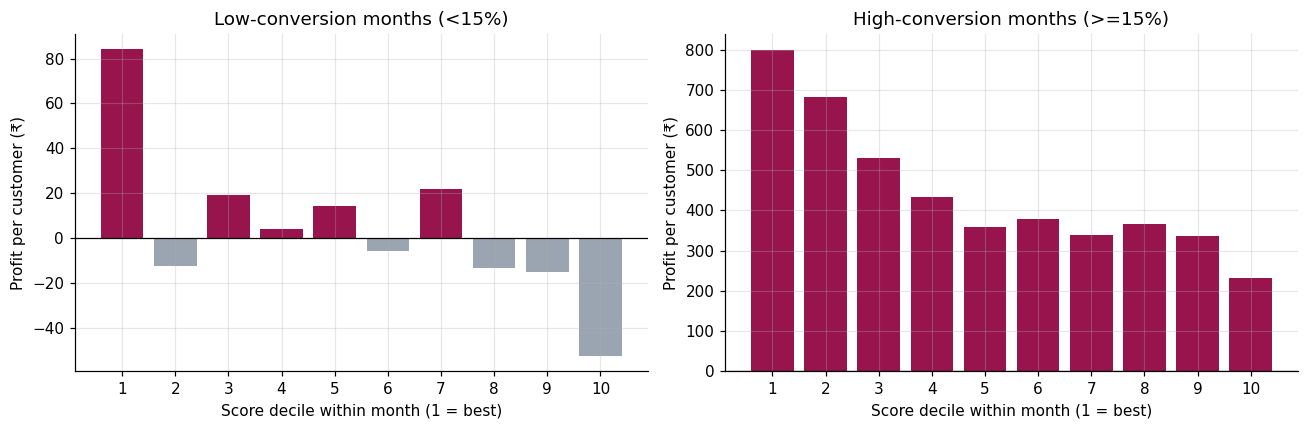

customers  conversion  calls_per_customer  profit_per_customer  total_profit
regime                         decile                                                                              
High-conversion months (>=15%) 1             780       0.595               1.869              798.846      623100.0
                               2             770       0.514               1.794              681.753      524950.0
                               3             771       0.416               1.894              529.831      408500.0
                               4             770       0.352               1.905              432.662      333150.0
                               5             775       0.301               1.822              359.871      278900.0
                               6             767       0.317               1.905              379.987      291450.0
                               7             768       0.290               1.935              338.802      260200.0
                               8             773       0.308               1.924              365.653      282650.0
                               9             769       0.286               1.840              337.126      259250.0
                               10            761       0.221               2.005              230.880      175700.0
Low-conversion months (<15%)   1             944       0.129               2.196               84.057       79350.0
                               2             942       0.068               2.290              -12.580      -11850.0
                               3             941       0.083               2.099               19.394       18250.0
                               4             943       0.073               2.113                4.083        3850.0
                               5             943       0.078               2.068               14.316       13500.0
                               6             941       0.068               2.156               -5.792       -5450.0
                               7             942       0.083               2.051               21.656       20400.0
                               8             942       0.063               2.142              -13.163      -12400.0
                               9             942       0.063               2.183              -15.180      -14300.0
                               10            940       0.051               2.583              -52.553      -49400.0

In [24]:
month_conv = wf.groupby('ym')['target'].transform('mean')
wf['regime'] = np.where(month_conv < 0.15, 'Low-conversion months (<15%)', 'High-conversion months (>=15%)')
dec_pnl = (wf.groupby(['regime', 'decile'])
             .agg(customers=('target', 'size'), conversion=('target', 'mean'), calls_per_customer=('campaign', 'mean'),
                  profit_per_customer=('profit', 'mean'), total_profit=('profit', 'sum'))
             .round(3))
print(wf.groupby('regime').agg(months=('ym', 'nunique'), customers=('target', 'size'), conversion=('target', 'mean')).round(3), '\n')

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, reg in zip(axes, ['Low-conversion months (<15%)', 'High-conversion months (>=15%)']):
    t = dec_pnl.loc[reg]
    ax.bar(t.index.astype(str), t['profit_per_customer'], color=np.where(t['profit_per_customer'] < 0, GREY, BRAND))
    ax.axhline(0, color='black', lw=0.8)
    ax.set_title(reg)
    ax.set_xlabel('Score decile within month (1 = best)')
    ax.set_ylabel('Profit per customer (₹)')
plt.tight_layout()
plt.show()
dec_pnl

In [25]:
# A business rule has to be simple: "skip the bottom k deciles", not a cherry-picked set of deciles
low = wf[wf['regime'].str.startswith('Low')]
skip_rows = []
for k in range(0, 6):
    kept = low[low['decile'] <= 10 - k]
    skip_rows.append({'skip_bottom_deciles': k,
                      'calls_cut': 1 - kept['campaign'].sum() / low['campaign'].sum(),
                      'subscribers_kept': kept['target'].sum() / low['target'].sum(),
                      'profit': kept['profit'].sum(),
                      'profit_change': kept['profit'].sum() - low['profit'].sum()})
skip_table = pd.DataFrame(skip_rows)
best_skip = skip_table.loc[skip_table['profit'].idxmax()]
print('Low-conversion months — skip the bottom k deciles of each month\'s list:')
print(skip_table.round(3).to_string(index=False), '\n')

# Capacity scenario (any regime): call only the top X% of each month's list
cap_rows = []
for top in [0.2, 0.3, 0.5, 0.7, 1.0]:
    k = wf[wf['pct_rank'] > 1 - top]
    cap_rows.append({'call_top_%': int(top * 100), 'customers': len(k),
                     'share_of_subscribers': k['target'].sum() / wf['target'].sum(),
                     'conversion': k['target'].mean(), 'profit_per_call': k['profit'].sum() / k['campaign'].sum()})
capacity = pd.DataFrame(cap_rows).round(3)
capacity

Low-conversion months — skip the bottom k deciles of each month's list:
 skip_bottom_deciles  calls_cut  subscribers_kept   profit  profit_change
                   0      0.000             1.000  41950.0            0.0
                   1      0.118             0.933  91350.0        49400.0
                   2      0.218             0.850 105650.0        63700.0
                   3      0.315             0.768 118050.0        76100.0
                   4      0.409             0.659  97650.0        55700.0
                   5      0.508             0.569 103100.0        61150.0 



,call_top_%,customers,share_of_subscribers,conversion,profit_per_call
0,20,3433,0.300,0.305,172.144
1,30,5148,0.414,0.281,156.350
2,50,8566,0.599,0.244,131.308
3,70,11995,0.773,0.225,117.086
4,100,17124,1.000,0.204,98.959


**Valuation findings**
- **In low-conversion months the bottom of the list loses money** (the bottom decile most of all) while the top decile is clearly profitable. Skipping the bottom three deciles cuts roughly a third of calls and turns a thin profit into a meaningfully larger one, at the cost of about a quarter of subscribers. The decile pattern in the middle is noisy — the low regime is only three months, one of them the cold-start month — so a simple "drop the bottom k" rule is safer than picking individual deciles.
- This is a diagnostic, not a backtested policy: it uses each month's realised regime. In practice the regime has to be estimated in advance, for example from a small randomised pilot at the start of each wave.
- **In high-conversion months every decile is profitable,** so the constraint is call-centre capacity, not economics. The capacity table shows the trade-off: calling the top half of each list captures ~60% of subscribers at roughly 1.3× the profit per call of calling everyone.
- **Recommendation:** run the score every wave; estimate the wave's base rate from a pilot; if the expected conversion of a decile is below break-even, drop it; otherwise call in score order until capacity runs out.

### 11.2 Sensitivity: break-even conversion per call
The skip/call decision hinges on value vs. cost, so here is the break-even per-call conversion across plausible ranges.

In [26]:
values = [1_000, 1_500, 2_500, 4_000]
costs = [30, 50, 80, 120]
sens = pd.DataFrame([[c / v for v in values] for c in costs],
                    index=[f'₹{c}/call' for c in costs], columns=[f'₹{v:,} per sub' for v in values])
(sens * 100).round(1).astype(str) + '%'

,"₹1,000 per sub","₹1,500 per sub","₹2,500 per sub","₹4,000 per sub"
₹30/call,3.0%,2.0%,1.2%,0.8%
₹50/call,5.0%,3.3%,2.0%,1.2%
₹80/call,8.0%,5.3%,3.2%,2.0%
₹120/call,12.0%,8.0%,4.8%,3.0%


## 12. Channel and contact-frequency policy (channel / offer mix)

### 12.1 Channel: mobile vs. landline

In [27]:
channel_year = df.pivot_table(index='year', columns='contact', values='target', aggfunc=['mean', 'size']).round(3)
tel = drivers.loc['contact = telephone']
print(f"Landline vs mobile, same month and same customer profile: odds ratio {tel['odds_ratio']:.2f} "
      f"(95% CI {tel['ci_low']:.2f}–{tel['ci_high']:.2f}), p = {tel['p_value']:.1e}")
channel_year

Landline vs mobile, same month and same customer profile: odds ratio 0.51 (95% CI 0.45–0.59), p = 4.9e-21


mean               size          
contact cellular telephone cellular telephone
year                                         
2008       0.057     0.039    13976     13714
2009       0.199     0.146    10498       942
2010       0.577     0.284     1670       388

Mobile contacts beat landline contacts in every year, and the gap holds after controlling for month and customer profile (odds ratio ≈ 0.5 for landline). **Recommendation:** collect and verify mobile numbers, and route landline-only customers to a cheaper channel (SMS, app notification, branch) unless they score in the top deciles.
Caveat: this is observational — the number on file may proxy for unobserved traits. Confirm with a randomised channel test before re-routing at scale.

### 12.2 How many times should we call the same customer?
The `campaign` column records how many calls each customer received. The conversion rate **of the k-th call** = customers who converted on call k ÷ customers who received at least k calls. A further call is worth making only while that rate stays above the per-call break-even.

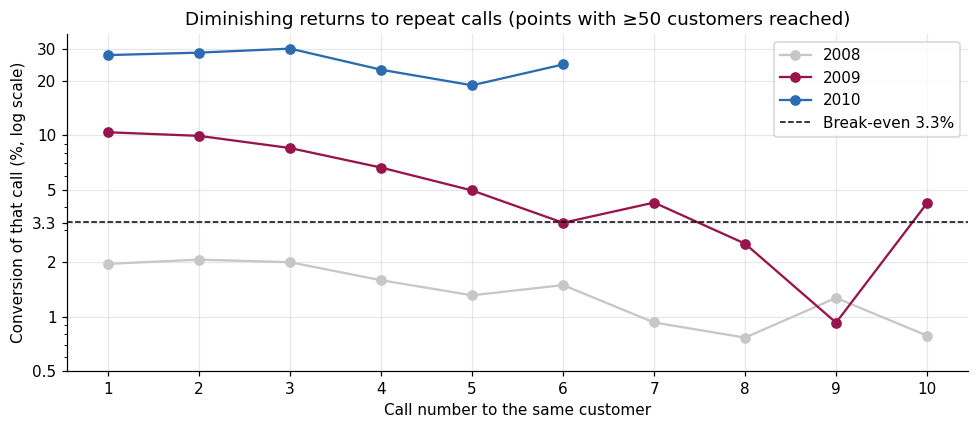

Profitable call attempts per customer, by year: {2008: 0, 2009: 5, 2010: '>= 6 (never below break-even in observed range)'}


,2008,2009,2010
call_number,,,
1,0.020,0.104,0.277
2,0.021,0.099,0.286
3,0.020,0.085,0.301
4,0.016,0.066,0.230
5,0.013,0.050,0.189
6,0.015,0.033,0.246
7,0.009,0.043,NaN
8,0.008,0.025,NaN
9,0.013,0.009,NaN


In [28]:
def per_call_conversion(frame, max_k=10):
    rows = []
    for k in range(1, max_k + 1):
        reached = (frame['campaign'] >= k).sum()
        converted = ((frame['campaign'] == k) & (frame['target'] == 1)).sum()
        rows.append({'call_number': k, 'customers_reached': reached, 'converted_on_this_call': converted,
                     'conversion_of_this_call': converted / reached if reached else np.nan})
    return pd.DataFrame(rows).set_index('call_number')


hazard = {y: per_call_conversion(df[df['year'] == y]) for y in [2008, 2009, 2010]}
fig, ax = plt.subplots(figsize=(9, 4))
for (y, h), c in zip(hazard.items(), ['#c7c7c7', BRAND, '#2b6cb0']):
    h = h[h['customers_reached'] >= 50]
    ax.plot(h.index, h['conversion_of_this_call'] * 100, marker='o', color=c, label=str(y))
ax.axhline(BREAKEVEN_PER_CALL * 100, color='black', ls='--', lw=1, label=f'Break-even {BREAKEVEN_PER_CALL:.1%}')
ax.set_yscale('log')
yt = [0.5, 1, 2, 3.3, 5, 10, 20, 30]
ax.set_yticks(yt)
ax.set_yticklabels([f'{t:g}' for t in yt])
ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_xticks(range(1, 11))
ax.set_xlabel('Call number to the same customer')
ax.set_ylabel('Conversion of that call (%, log scale)')
ax.set_title('Diminishing returns to repeat calls (points with ≥50 customers reached)')
ax.legend()
plt.tight_layout()
plt.show()


def contact_cap(h, min_reached=50):
    """Last call number before conversion first drops to/below break-even (ignoring thin tails)."""
    h = h[h['customers_reached'] >= min_reached]
    below = h[h['conversion_of_this_call'] <= BREAKEVEN_PER_CALL]
    if below.empty:
        return f'>= {int(h.index.max())} (never below break-even in observed range)'
    return int(below.index.min()) - 1


caps = {y: contact_cap(h) for y, h in hazard.items()}
print('Profitable call attempts per customer, by year:', caps)
pd.concat({y: h['conversion_of_this_call'].where(h['customers_reached'] >= 50) for y, h in hazard.items()},
          axis=1).round(3)

Each extra call converts less than the one before. Under the illustrative economics, in 2008 even the first call was below break-even; in 2009 calls stayed profitable through the fifth attempt and fell below break-even at the sixth; in 2010 the regime was so strong that every attempt with enough data paid off. **Recommendation:** set a regime-dependent contact cap — around 3–5 attempts in a normal year, fewer when the base rate is low — and stop dialling as soon as the expected conversion of the next attempt drops below break-even.
Caveat: customers who need many calls differ from those who answer early, so this curve mixes customer type with call fatigue. A cap A/B test would separate the two.

## 13. Summary of findings

In [29]:
def lakh(x):
    return f"{'-' if x < 0 else ''}₹{abs(x) / 1e5:,.1f} lakh"


low_dec = dec_pnl.loc['Low-conversion months (<15%)']
top30 = capacity.loc[capacity['call_top_%'] == 30].iloc[0]
summary = f"""
DATA & VALIDATION
- 41,188 calls, May-08 to Nov-10; conversion moved from {pnl.loc[2008, 'conv_per_customer']:.1%} (2008) to {pnl.loc[2010, 'conv_per_customer']:.1%} (2010).
- Call duration excluded (leakage). Validation is out-of-time with an untouched 2010 holdout.
- Random-split AUC overstates real performance: clean model {trap.iloc[0]['random_split_auc']:.2f} vs {trap.iloc[0]['out_of_time_auc']:.2f} out-of-time;
  kitchen-sink model {trap.iloc[2]['random_split_auc']:.2f} vs {trap.iloc[2]['out_of_time_auc']:.2f}.

PROPENSITY MODEL ({CHOSEN}, customer features only)
- 2010 holdout AUC {holdout_auc:.3f} (within-month {holdout_wm_auc:.3f}); walk-forward mean AUC from Mar-09: {wf_mean_auc:.2f}.
- Top decile converts at {gains.loc[1, 'conversion']:.1%} vs {HOLDOUT['target'].mean():.1%} average (lift {gains.loc[1, 'lift']:.2f}x);
  top 50% of customers capture {gains.loc[5, 'cum_pct_subscribers']:.0%} of subscribers.
- F1 (needs a cut-off): best possible on 2010 {F1_MAX:.3f} vs {F1_BASELINE:.3f} for calling everyone; {F1_DEV_TUNED:.3f} with a 2009-tuned cut-off.
  Walk-forward (13,498 customers): F1 {current['walkforward_f1']:.3f}, precision {current['walkforward_precision']:.3f} vs {attempt.loc['Call everyone (no model)', 'walkforward_f1']:.3f} / {attempt.loc['Call everyone (no model)', 'walkforward_precision']:.3f} calling everyone;
  none of 5 legitimate model changes beat it. Precision at top 30% of the holdout list: {operating_points.loc[30, 'precision']:.1%}.
- Raw probabilities are off under drift: mean prediction {HOLDOUT['score'].mean():.1%} vs actual {HOLDOUT['target'].mean():.1%};
  Platt recalibration on the last quarter -> {HOLDOUT['score_cal'].mean():.1%} (slope {platt.coef_[0][0]:.2f}: model over-confident in the new regime).

ROOT CAUSE
- Customer mix explains {mix / total:.0%} of the 2008->2010 conversion rise; {rate / total:.0%} is within-segment (environment / offer / list selection).
- First wave (May-Aug 2008) had almost no rankable signal (in-period CV AUC {signal.iloc[0]['in_period_cv_auc']:.2f}).
- Holding campaign month fixed: past success OR {drivers.loc['poutcome = success', 'odds_ratio']:.1f}x, landline OR {tel['odds_ratio']:.2f}x;
  most job/education gaps in raw reports are timing artefacts.

VALUE (illustrative: ₹{VALUE_PER_SUB:,.0f} per subscriber, ₹{COST_PER_CALL} per call)
- P&L: 2008 {lakh(pnl.loc[2008, 'profit'])}; 2009 {lakh(pnl.loc[2009, 'profit'])}; 2010 {lakh(pnl.loc[2010, 'profit'])}.
- Low-conversion months: bottom decile ₹{low_dec.loc[10, 'profit_per_customer']:,.0f}/customer vs top decile ₹{low_dec.loc[1, 'profit_per_customer']:,.0f}/customer.
  Best simple rule: skip bottom {int(best_skip['skip_bottom_deciles'])} deciles -> profit {lakh(best_skip['profit_change'])} better,
  {best_skip['calls_cut']:.0%} fewer calls, {best_skip['subscribers_kept']:.0%} of subscribers kept.
- Capacity: calling the top 30% of each month's list captures {top30['share_of_subscribers']:.0%} of subscribers.

CHANNEL & CONTACT POLICY
- Prioritise mobile numbers; landline has ~half the odds.
- Profitable call attempts per customer by year: {caps}.
"""
print(summary)


DATA & VALIDATION
- 41,188 calls, May-08 to Nov-10; conversion moved from 4.8% (2008) to 52.1% (2010).
- Call duration excluded (leakage). Validation is out-of-time with an untouched 2010 holdout.
- Random-split AUC overstates real performance: clean model 0.69 vs 0.62 out-of-time;
  kitchen-sink model 0.75 vs 0.60.

PROPENSITY MODEL (Logistic regression, customer features only)
- 2010 holdout AUC 0.679 (within-month 0.678); walk-forward mean AUC from Mar-09: 0.62.
- Top decile converts at 79.1% vs 52.1% average (lift 1.52x);
  top 50% of customers capture 61% of subscribers.
- F1 (needs a cut-off): best possible on 2010 0.713 vs 0.685 for calling everyone; 0.693 with a 2009-tuned cut-off.
  Walk-forward (13,498 customers): F1 0.492, precision 0.376 vs 0.393 / 0.245 calling everyone;
  none of 5 legitimate model changes beat it. Precision at top 30% of the holdout list: 75.2%.
- Raw probabilities are off under drift: mean prediction 30.9% vs actual 52.1%;
  Platt recalibration on the 

### Recommendations for the business
1. **Score before every wave.** Call in score order. When a pilot shows the wave's base rate is low, drop deciles whose expected conversion is below break-even.
2. **Start with previous responders.** Past success is the strongest within-month signal (~3× odds).
3. **Shift to mobile.** Verify mobile numbers; route landline-only, low-score customers to cheaper channels.
4. **Cap repeat calls** at the point where the next attempt's expected conversion falls below break-even (about 3–5 attempts in a normal year).
5. **Monitor two things monthly:** AUC (ranking — retrain if it decays below ~0.6) and calibration (level — recalibrate from the latest results).

### Limitations
- The economics are illustrative; the conclusions about *which* deciles to drop depend on the real spread and call cost.
- Data covers a single Portuguese bank in 2008–10, a crisis period. Directions (past responders, mobile, contact caps, out-of-time validation) transfer; exact numbers do not.
- Channel and contact-cap effects are observational. Confirm them with A/B tests before changing operations.
- No customer balance, tenure or transaction data. In a real BIU setting those would be the biggest upgrade to the score.

### Next steps
- Macro indicators: they helped on 2010 but not on 2009 folds (§7.1) — test them in a separate timing model as more periods arrive.
- Uplift modelling (who converts *because* of the call) using a randomised control group.
- Separate volume/timing model using the macro indicators: *how many* to call this month.
- A Power BI / Excel dashboard on the exported tables below: monthly volume, conversion, AUC and decile P&L.

## 14. Export tables for an Excel / Power BI dashboard

In [30]:
exports = {
    'holdout_2010_scored.csv': HOLDOUT[['period', 'age', 'job', 'contact', 'poutcome', 'target', 'score', 'score_cal', 'decile']]
                               .rename(columns={'score': 'score_raw', 'score_cal': 'score_recalibrated'}),
    'holdout_gains_table.csv': gains.reset_index(),
    'monthly_kpis_and_model_auc.csv': monthly.merge(wf_monitor[['ym', 'auc']], on='ym', how='left'),
    'segment_index_job.csv': segments['job'].reset_index(),
    'segment_index_age.csv': segments['age_band'].reset_index(),
    'driver_odds_ratios.csv': drivers.reset_index().rename(columns={'index': 'driver'}),
    'pnl_by_year.csv': pnl.reset_index(),
    'decile_pnl_by_regime.csv': dec_pnl.reset_index(),
    'skip_rule_low_conversion.csv': skip_table,
    'model_selection_backtest.csv': selection,
    'validation_trap.csv': trap.reset_index(),
    'f1_holdout_rules.csv': f1_table.reset_index(),
    'f1_by_window.csv': f1_by_window.reset_index(),
    'f1_precision_improvement_attempt.csv': attempt.reset_index(),
    'precision_operating_points.csv': operating_points.reset_index(),
}
for name, table in exports.items():
    table.to_csv(os.path.join(OUT_DIR, name), index=False)
print('Saved to', os.path.abspath(OUT_DIR))
for name in exports:
    print(' -', name)

Saved to /home/claude/nb/outputs
 - holdout_2010_scored.csv
 - holdout_gains_table.csv
 - monthly_kpis_and_model_auc.csv
 - segment_index_job.csv
 - segment_index_age.csv
 - driver_odds_ratios.csv
 - pnl_by_year.csv
 - decile_pnl_by_regime.csv
 - skip_rule_low_conversion.csv
 - model_selection_backtest.csv
 - validation_trap.csv
 - f1_holdout_rules.csv
 - f1_by_window.csv
 - f1_precision_improvement_attempt.csv
 - precision_operating_points.csv
